### Task 1: Data Preparation and Feature Engineering

In [1]:
# Install the packages required for data collection and analysis.
%pip -q install yfinance lxml html5lib beautifulsoup4

In [2]:
# Import the libraries and define the project folders and analysis settings.
import json
import hashlib
import sys
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import yfinance as yf
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import sklearn

project_dir = Path.cwd() / 'stock_analysis'

raw_dir = project_dir / 'market_data'

results_dir = project_dir / 'output'

raw_dir.mkdir(parents=True, exist_ok=True)

results_dir.mkdir(parents=True, exist_ok=True)

period_start = '2021-01-01'

period_end = '2025-01-01'

seed_value = 42

MIN_CLUSTER_FRAC = 0.03

selected_k_override = {}

wiki_url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.alpha': 0.2,
    'axes.spines.top': False,
    'axes.spines.right': False
})

print("Libraries imported successfully.")

print("Folders created successfully.")

Libraries imported successfully.
Folders created successfully.


### 1.1 Ticker selection and data acquisition

In [3]:
def write_json(target_path, payload):

    target_path.write_text(
        json.dumps(payload, indent=2, default=str),
        encoding='utf-8'
    )

def file_sha256(target_path):

    return hashlib.sha256(target_path.read_bytes()).hexdigest()

def fetch_market_data():

    constituents_path = raw_dir / 'constituents.csv'

    if constituents_path.exists():

        constituents = pd.read_csv(constituents_path)

    else:

        constituents = pd.read_html(
            wiki_url,
            storage_options={'User-Agent': 'Mozilla/5.0'}
        )[0]

        needed_cols = [
            'Symbol',
            'Security',
            'GICS Sector',
            'GICS Sub-Industry'
        ]

        if not all(col in constituents.columns for col in needed_cols):

            raise RuntimeError("The company data format has changed.")

        constituents = constituents[needed_cols].copy()

        constituents['retrieved_utc'] = datetime.now(timezone.utc).isoformat()

        constituents.to_csv(constituents_path, index=False)

    constituents['YahooTicker'] = constituents['Symbol'].str.replace(
        '.', '-', regex=False
    )

    index_symbol = '^GSPC'

    company_tickers = constituents['YahooTicker'].drop_duplicates().tolist()

    download_queue = company_tickers + [index_symbol]

    failed_list = []

    for batch_start in range(0, len(download_queue), 25):

        current_batch = download_queue[batch_start:batch_start + 25]

        for symbol in current_batch:

            file_safe_symbol = symbol.replace('^', 'INDEX_')

            price_path = raw_dir / f"{file_safe_symbol}.csv"

            if price_path.exists():

                continue

            try:

                price_history = yf.download(
                    symbol,
                    start=period_start,
                    end=period_end,
                    interval='1d',
                    auto_adjust=False,
                    actions=True,
                    progress=False,
                    threads=False,
                    multi_level_index=False
                )

                if price_history is None or price_history.empty:

                    failed_list.append(symbol)

                    continue

                if isinstance(price_history.columns, pd.MultiIndex):

                    price_history.columns = price_history.columns.get_level_values(0)

                price_history.index = pd.to_datetime(
                    price_history.index
                ).tz_localize(None).normalize()

                price_history.index.name = 'Date'

                price_history.to_csv(price_path)

            except Exception as err:

                failed_list.append(symbol)

                print("Download failed:", symbol, str(err)[:150])

    index_path = raw_dir / 'INDEX_GSPC.csv'

    if not index_path.exists():

        raise RuntimeError(
            "Benchmark data is unavailable. Please check the download."
        )

    pd.Series(failed_list, name='FailedTicker').to_csv(results_dir / 'failed_downloads.csv', index=False)

    print("Stock data downloading completed.")

    print("Failed downloads:", len(failed_list))

    return constituents

def load_price_file(symbol):

    file_safe_symbol = symbol.replace('^', 'INDEX_')

    price_path = raw_dir / f"{file_safe_symbol}.csv"

    if not price_path.exists():

        return None

    prices = pd.read_csv(
        price_path,
        index_col='Date',
        parse_dates=True
    )

    prices.index = pd.to_datetime(
        prices.index
    ).tz_localize(None).normalize()

    return prices.sort_index()

In [4]:
# Retrieve the company list and market prices, then record the data source details.
sp500_info = fetch_market_data()

display(sp500_info.head())

print("Total company records:", len(sp500_info))

print("Data retrieved on:", sp500_info['retrieved_utc'].iloc[0])

package_versions = {
    'Python': sys.version.split()[0],
    'Pandas': pd.__version__,
    'NumPy': np.__version__,
    'SciPy': scipy.__version__,
    'Scikit-learn': sklearn.__version__,
    'Matplotlib': matplotlib.__version__,
    'yfinance': yf.__version__
}

display(pd.Series(package_versions, name='Version').to_frame())

write_json(results_dir / 'provenance.json', {
    'source': wiki_url,
    'price_source': 'Yahoo Finance via yfinance (auto_adjust=False; Close and Adj Close both kept)',
    'benchmark': '^GSPC',
    'data_retrieved_date': sp500_info['retrieved_utc'].iloc[0],
    'study_period': [period_start, period_end],
    'library_versions': package_versions,
    'file_hashes': {
        csv_file.name: file_sha256(csv_file)
        for csv_file in raw_dir.glob('*.csv')
    }
})

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Stock data downloading completed.
Failed downloads: 5


,Symbol,Security,GICS Sector,GICS Sub-Industry,retrieved_utc,YahooTicker
0,MMM,3M,Industrials,Industrial Conglomerates,2026-11-25T03:11:15.196028+00:00,MMM
1,AOS,A. O. Smith,Industrials,Building Products,2026-11-25T03:11:15.196028+00:00,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-25T03:11:15.196028+00:00,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,2026-11-25T03:11:15.196028+00:00,ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-25T03:11:15.196028+00:00,ACN


Total company records: 503
Data retrieved on: 2026-11-25T03:11:15.196028+00:00


,Version
Python,3.13.18
Pandas,2.2.3
NumPy,2.4.6
SciPy,1.16.3
Scikit-learn,1.6.1
Matplotlib,3.10.0
yfinance,0.2.66


1.2 Data validation and alignment

In [5]:
# Load and validate benchmark prices before comparing individual shares.
index_prices = load_price_file('^GSPC')

index_prices = index_prices.loc[
    (index_prices.index >= period_start) &
    (index_prices.index < period_end)
]

assert not index_prices.index.duplicated().any(), "Duplicate benchmark dates found"

assert index_prices.index.min() == pd.Timestamp('2021-01-04')

assert index_prices.index.max() == pd.Timestamp('2024-12-31')

assert np.isfinite(index_prices['Adj Close']).all()

assert index_prices['Adj Close'].gt(0).all()

as_of_date = index_prices.index.max()

friday_calendar = pd.date_range(
    '2021-01-08',
    '2024-12-27',
    freq='W-FRI'
)

clean_prices = {}

check_records = []

for firm in sp500_info.itertuples(index=False):

    symbol = firm.YahooTicker

    daily_prices = load_price_file(symbol)

    rejection_reasons = []

    n_splits = np.nan

    n_dividends = np.nan

    n_missing = np.nan

    n_split_lookback = np.nan

    n_jumps = np.nan

    n_adj_above = np.nan

    mandatory_cols = [
        'Close',
        'Adj Close',
        'Volume',
        'Stock Splits',
        'Dividends'
    ]

    if daily_prices is None:

        rejection_reasons.append('Unavailable data')

    else:

        daily_prices = daily_prices.loc[
            (daily_prices.index >= period_start) &
            (daily_prices.index < period_end)
        ]

        n_missing = len(
            index_prices.index.difference(daily_prices.index)
        )

        if daily_prices.index.duplicated().any():

            rejection_reasons.append('Duplicate dates')

        if n_missing or not daily_prices.index.isin(
            index_prices.index
        ).all():

            rejection_reasons.append(
                'Incomplete or unequal trading history'
            )

        if not set(mandatory_cols).issubset(daily_prices.columns):

            rejection_reasons.append('Missing required fields')

        else:

            if not np.isfinite(
                daily_prices[mandatory_cols].to_numpy()
            ).all():

                rejection_reasons.append(
                    'Missing or nonfinite values'
                )

            if daily_prices[['Close', 'Adj Close']].le(0).any().any():

                rejection_reasons.append('Nonpositive prices')

            if daily_prices['Volume'].le(0).any():

                rejection_reasons.append('Nonpositive volume')

            n_splits = int(
                daily_prices['Stock Splits'].ne(0).sum()
            )

            n_dividends = int(
                daily_prices['Dividends'].ne(0).sum()
            )

            n_split_lookback = int(daily_prices['Stock Splits'].tail(80).ne(0).sum())

            n_jumps = int((
                daily_prices['Close'].pct_change().abs().gt(0.4)
                & daily_prices['Stock Splits'].eq(0)
            ).sum())

            n_adj_above = int(
                (daily_prices['Adj Close'] > daily_prices['Close'] * 1.0001).sum()
            )

            if (
                daily_prices['Stock Splits'].lt(0).any()
                or daily_prices['Dividends'].lt(0).any()
            ):

                rejection_reasons.append(
                    'Invalid corporate action values'
                )

    if not rejection_reasons:

        clean_prices[symbol] = daily_prices

    check_records.append({
        'Ticker': symbol,
        'MissingSessions': n_missing,
        'SplitDays': n_splits,
        'DividendDays': n_dividends,
        'SplitsInRFMLookback': n_split_lookback,
        'UnexplainedJumps': n_jumps,
        'AdjCloseAboveClose': n_adj_above,
        'Status': 'Valid' if not rejection_reasons else 'Excluded',
        'Reason': '; '.join(rejection_reasons)
    })

audit_table = pd.DataFrame(
    check_records
).set_index('Ticker')

print("Final observation date:", as_of_date.date())

assert clean_prices, "No valid company stock data found"

display(audit_table)

print("Valid companies:", len(clean_prices))

display(audit_table.loc[audit_table["Status"] == "Excluded", "Reason"].value_counts().to_frame("Shares"))

Final observation date: 2024-12-31


,MissingSessions,SplitDays,DividendDays,SplitsInRFMLookback,UnexplainedJumps,AdjCloseAboveClose,Status,Reason
Ticker,,,,,,,,
MMM,0.0,1.0,16.0,0.0,0.0,0.0,Valid,
AOS,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ABT,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ABBV,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ACN,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
...,...,...,...,...,...,...,...,...
XYL,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
YUM,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ZBRA,0.0,0.0,0.0,0.0,0.0,0.0,Valid,


Valid companies: 486


,Shares
Reason,
Incomplete or unequal trading history,10
Unavailable data,5
Nonpositive volume,2


1.3 Weekly return and weekly beta

1.3.1 Mean weekly return

In [6]:
# Convert daily adjusted closing prices into aligned weekly returns.
def compute_weekly_returns(daily_prices):

    weekly_close = daily_prices['Adj Close'].resample('W-FRI').last()

    weekly_close = weekly_close.reindex(friday_calendar)

    weekly_change = weekly_close.pct_change(fill_method=None)

    return weekly_change

index_returns = compute_weekly_returns(
    index_prices
).dropna()

stock_returns = pd.DataFrame({
    symbol: compute_weekly_returns(prices)
    for symbol, prices in clean_prices.items()
})

stock_returns = stock_returns.reindex(
    index_returns.index
)

assert stock_returns.notna().all().all(), "Missing weekly returns found"

stock_table = sp500_info.set_index('YahooTicker').loc[
    list(clean_prices),
    ['Security', 'GICS Sector']
].copy()

stock_table.index.name = 'Ticker'

stock_table.rename(
    columns={'GICS Sector': 'Sector'},
    inplace=True
)

stock_table['MeanWeeklyReturn'] = stock_returns.mean()

stock_table['WeeklyN'] = stock_returns.count()

print("Aligned weekly return observations:", len(index_returns))

print("First / last return week:", index_returns.index.min().date(), index_returns.index.max().date())

assert (stock_returns.index == index_returns.index).all()

sessions_per_week = index_prices['Adj Close'].resample('W-FRI').count().reindex(index_returns.index)

print("Holiday-shortened weeks retained:", int((sessions_per_week < 5).sum()))

chk = next(iter(clean_prices))

weekly_px = clean_prices[chk]['Adj Close'].resample('W-FRI').last()

manual = weekly_px.loc[index_returns.index] / weekly_px.shift(1).loc[index_returns.index] - 1

assert np.allclose(manual.values, stock_returns[chk].values)

display(
    stock_table[['MeanWeeklyReturn', 'WeeklyN']]
)

Aligned weekly return observations: 207
First / last return week: 2021-01-15 2024-12-27
Holiday-shortened weeks retained: 37


,MeanWeeklyReturn,WeeklyN
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
...,...,...
XYL,0.001358,207
YUM,0.001807,207
ZBRA,0.001181,207


1.3.2 Weekly beta

In [7]:
# Calculate each share’s beta using its covariance with benchmark returns.
index_var = index_returns.var()

assert index_var > 0

stock_table['WeeklyBeta'] = stock_returns.apply(
    lambda one_stock:
    one_stock.cov(index_returns) / index_var
)

display(
    stock_table[['WeeklyBeta', 'WeeklyN']]
)

assert np.isclose(
    np.polyfit(index_returns.values, stock_returns[chk].values, 1)[0],
    stock_table.loc[chk, 'WeeklyBeta']
)

print("Aligned weekly observations used for beta:", len(index_returns))

,WeeklyBeta,WeeklyN
Ticker,,
MMM,0.869079,207
AOS,1.042805,207
ABT,0.583542,207
ABBV,0.425366,207
ACN,1.143300,207
...,...,...
XYL,1.138379,207
YUM,0.631433,207
ZBRA,1.618418,207


Aligned weekly observations used for beta: 207


1.4.1 Recency

In [8]:
# Identify qualifying high-volume events using the previous 20 trading days.
volume_events = {}

for symbol, daily_prices in clean_prices.items():

    prior_mean_volume = (
        daily_prices['Volume']
        .shift(1)
        .rolling(20, min_periods=20)
        .mean()
    )

    spike_flag = (
        daily_prices['Volume'].gt(2 * prior_mean_volume)
        & prior_mean_volume.notna()
    )

    assert prior_mean_volume.tail(60).notna().all()

    volume_events[symbol] = pd.DataFrame({
        'Close': daily_prices['Close'],
        'Volume': daily_prices['Volume'],
        'PreviousAverageVolume': prior_mean_volume,
        'VolumeThreshold': 2 * prior_mean_volume,
        'Qualifies': spike_flag
    })

assert all(t.index[-1] == as_of_date for t in volume_events.values())

for symbol in list(volume_events)[:5]:

    vol = clean_prices[symbol]['Volume']

    for pos in range(len(vol) - 60, len(vol)):

        base = vol.iloc[pos - 20:pos].mean()

        assert (vol.iloc[pos] > 2 * base) == bool(volume_events[symbol]['Qualifies'].iloc[pos])

last_spike_dates = pd.Series({
    symbol: spike_table.index[spike_table['Qualifies']].max()
    for symbol, spike_table in volume_events.items()
})

stock_table['ObservationDate'] = as_of_date

stock_table['LatestEvent'] = last_spike_dates

stock_table['R'] = (
    as_of_date - last_spike_dates
).dt.days

no_spike_tickers = stock_table.index[
    stock_table['R'].isna()
]

audit_table.loc[
    no_spike_tickers, 'Status'
] = 'Excluded'

audit_table.loc[
    no_spike_tickers, 'Reason'
] = 'No qualifying high-volume event; Recency missing'

print("Shares with an event on the observation date (R = 0):", int((stock_table['R'] == 0).sum()))

print("Shares with no qualifying event (excluded from RFM):", len(no_spike_tickers))

display(
    stock_table[['ObservationDate', 'LatestEvent', 'R']]
)

Shares with an event on the observation date (R = 0): 0
Shares with no qualifying event (excluded from RFM): 0


,ObservationDate,LatestEvent,R
Ticker,,,
MMM,2024-12-31,2024-12-20,11
AOS,2024-12-31,2024-12-20,11
ABT,2024-12-31,2024-12-20,11
ABBV,2024-12-31,2024-12-20,11
ACN,2024-12-31,2024-12-20,11
...,...,...,...
XYL,2024-12-31,2024-11-25,36
YUM,2024-12-31,2024-11-05,56
ZBRA,2024-12-31,2024-12-20,11


1.4.2 Frequency

In [9]:
# Count qualifying events in the latest 60 trading days to calculate Frequency.
stock_table['F'] = pd.Series({
    symbol: int(spike_table['Qualifies'].tail(60).sum())
    for symbol, spike_table in volume_events.items()
})

display(stock_table[['F']])

,F
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
...,...
XYL,3
YUM,1
ZBRA,4


1.4.3 Monetary

In [10]:
# Calculate Monetary value from closing price and trading volume over the analysis window.
stock_table['M'] = pd.Series({
    symbol: (
        spike_table['Close'] * spike_table['Volume']
    ).tail(60).sum()
    for symbol, spike_table in volume_events.items()
})

display(stock_table[['M']])

,M
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
...,...
XYL,1.017679e+10
YUM,1.339492e+10
ZBRA,8.326927e+09


1.5 Metric interpretation and supporting evidence

In [11]:
# Keep records with a valid Recency value for the RFM analysis.
final_table = stock_table.dropna(subset=['R']).reset_index()

final_table['R'] = final_table['R'].astype(int)

audit_table.loc[pd.Index(final_table['Ticker']), 'Status'] = 'Included'

audit_table.to_csv(results_dir / 'inclusion_exclusion_log.csv')

display(audit_table['Status'].value_counts().to_frame('Shares'))

display(audit_table[audit_table['Status'] != 'Included'])

assert len(final_table) >= 9, "Not enough companies for cluster counts 2 to 8"

core_metrics = ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']

display(final_table[core_metrics].describe())

display(final_table[core_metrics].skew().to_frame('Skewness').round(3))

sample_firm = final_table.iloc[0]

sample_events = volume_events[sample_firm.Ticker]

sample_recent60 = sample_events.tail(60).copy()

sample_recent60['TradingValue'] = sample_recent60['Close'] * sample_recent60['Volume']

display(sample_firm[['Ticker', 'ObservationDate', 'LatestEvent', 'R', 'F', 'M']].to_frame('Worked Example'))

display(sample_events.loc[[sample_firm.LatestEvent]])

display(sample_recent60)

assert sample_recent60['Qualifies'].sum() == sample_firm.F

assert np.isclose(sample_recent60['TradingValue'].sum(), sample_firm.M)

assert (as_of_date - sample_firm.LatestEvent).days == sample_firm.R

assert np.isclose(
    sample_events.loc[sample_firm.LatestEvent, 'PreviousAverageVolume'],
    sample_events.loc[:sample_firm.LatestEvent, 'Volume'].iloc[-21:-1].mean()
)

provenance_record = json.loads((results_dir / 'provenance.json').read_text())

provenance_record['observation_date'] = str(as_of_date.date())

write_json(results_dir / 'provenance.json', provenance_record)

print("Task 1 completed successfully.")

print("Final number of companies:", len(final_table))

,Shares
Status,
Included,486
Excluded,17


,MissingSessions,SplitDays,DividendDays,SplitsInRFMLookback,UnexplainedJumps,AdjCloseAboveClose,Status,Reason
Ticker,,,,,,,,
APP,70.0,0.0,0.0,0.0,1.0,0.0,Excluded,Incomplete or unequal trading history
COIN,69.0,0.0,0.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
CEG,263.0,0.0,12.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
EXE,26.0,0.0,15.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
FDXF,NaN,NaN,NaN,NaN,NaN,NaN,Excluded,Unavailable data
FERG,0.0,0.0,13.0,0.0,0.0,0.0,Excluded,Nonpositive volume
GEHC,492.0,0.0,7.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
GEV,812.0,0.0,1.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
HONA,NaN,NaN,NaN,NaN,NaN,NaN,Excluded,Unavailable data


,MeanWeeklyReturn,WeeklyBeta,R,F,M
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055453,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950610,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


,Skewness
MeanWeeklyReturn,0.868
WeeklyBeta,1.104
R,3.646
F,0.425
M,11.684


,Worked Example
Ticker,MMM
ObservationDate,2024-12-31 00:00:00
LatestEvent,2024-12-20 00:00:00
R,11
F,4
M,25991458733.34198


,Close,Volume,PreviousAverageVolume,VolumeThreshold,Qualifies
Date,,,,,
2024-12-20,129.279999,8351300,3027540.0,6055080.0,True


,Close,Volume,PreviousAverageVolume,VolumeThreshold,Qualifies,TradingValue
Date,,,,,,
2024-10-07,134.850006,2254200,3568210.0,7136420.0,False,3.039789e+08
2024-10-08,134.690002,2882100,3500105.0,7000210.0,False,3.881901e+08
2024-10-09,135.009995,2671400,3507585.0,7015170.0,False,3.606657e+08
2024-10-10,133.460007,3060100,3476965.0,6953930.0,False,4.084010e+08
2024-10-11,134.750000,3103600,3431030.0,6862060.0,False,4.182101e+08
2024-10-14,135.759995,2207900,3452705.0,6905410.0,False,2.997445e+08
2024-10-15,135.729996,2465800,3409635.0,6819270.0,False,3.346830e+08
2024-10-16,136.350006,2021100,3334475.0,6668950.0,False,2.755770e+08
2024-10-17,135.679993,2328500,3287485.0,6574970.0,False,3.159309e+08


Task 1 completed successfully.
Final number of companies: 486




## Task 2 – Stock segmentation and sensitivity analysis


2.1 Feature preparation

,Skewness,IQR Outliers
MeanWeeklyReturn,0.8675,15
WeeklyBeta,1.1036,10
R,3.6458,115
F,0.4247,2
M,11.6838,45
LogM,1.0791,13


,raw_skew,log1p_skew
R,3.646,1.583
F,0.425,-0.928


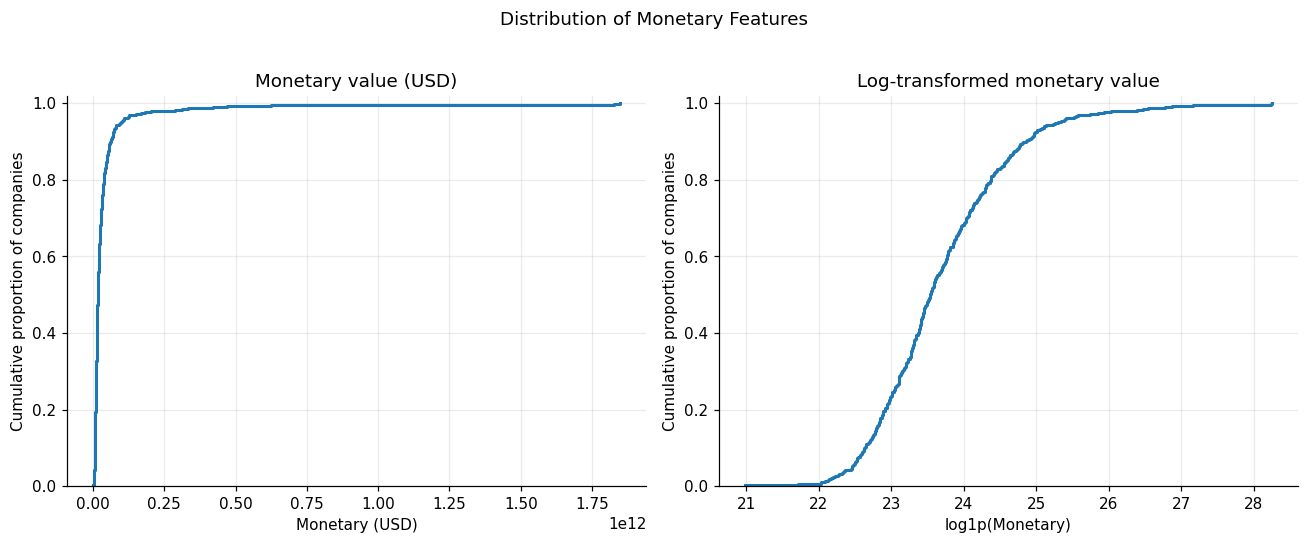

In [12]:
# Prepare the selected risk and RFM measures for clustering.
features = final_table.copy()

metrics = [
    'MeanWeeklyReturn',
    'WeeklyBeta',
    'R',
    'F',
    'M'
]

features['LogM'] = np.log1p(features['M'])

feature_columns = metrics + ['LogM']

q1_values = features[feature_columns].quantile(0.25)
q3_values = features[feature_columns].quantile(0.75)
iqr_values = q3_values - q1_values

is_outlier = (
    (features[feature_columns] < q1_values - 1.5 * iqr_values)
    | (features[feature_columns] > q3_values + 1.5 * iqr_values)
)

skew_and_outliers = pd.DataFrame({
    'Skewness': features[feature_columns].skew(),
    'IQR Outliers': is_outlier.sum()
})
display(skew_and_outliers.round(4))

skew_check = pd.DataFrame({
    'raw_skew': features[['R', 'F']].skew(),
    'log1p_skew': np.log1p(features[['R', 'F']]).skew()
})
display(skew_check.round(3))

# Empirical cumulative distribution curves show every observed value.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, column, title, xlabel in [
    (axes[0], 'M', 'Monetary value (USD)', 'Monetary (USD)'),
    (axes[1], 'LogM', 'Log-transformed monetary value', 'log1p(Monetary)')
]:
    values = np.sort(features[column].dropna().to_numpy())
    cumulative = np.arange(1, len(values) + 1) / len(values)
    ax.step(values, cumulative, where='post', linewidth=2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Cumulative proportion of companies')
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)

fig.suptitle('Distribution of Monetary Features', y=1.02)
fig.tight_layout()
plt.show()


In [13]:
# Store standardised feature sets separately for the clustering methods.
scaled_matrices = {}

feature_groups = {
    'risk': ['MeanWeeklyReturn', 'WeeklyBeta'],
    'rfm': ['R', 'F', 'LogM']
}

pd.set_option('display.max_rows', None)

for set_name, set_columns in feature_groups.items():

    z_scaler = StandardScaler()

    z_values = z_scaler.fit_transform(
        features[set_columns]
    )

    scaled_matrices[set_name] = pd.DataFrame(
        z_values,
        columns=set_columns,
        index=features['Ticker']
    )

    print("Standardised", set_name.upper(), "features")

    display(scaled_matrices[set_name])

pd.reset_option('display.max_rows')

Standardised RISK features


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
MMM,-0.647333,-0.257092
AOS,-0.327124,0.169836
ABT,-0.711938,-0.958797
ABBV,0.336742,-1.347514
ACN,-0.181507,0.416802
ADBE,-0.704886,1.424924
AMD,0.289522,2.221388
AES,-1.614635,0.418307
AFL,0.810554,-0.654917


Standardised RFM features


,R,F,LogM
Ticker,,,
MMM,-0.441238,0.759941,0.317572
AOS,-0.441238,-0.744463,-1.488397
ABT,-0.441238,-1.496666,0.640699
ABBV,-0.441238,0.007739,1.345132
ACN,-0.441238,-0.744463,1.054229
ADBE,-0.112915,0.007739,1.780920
AMD,-0.112915,0.759941,2.961937
AES,1.575603,0.007739,-0.577245
AFL,-0.441238,-0.744463,-0.395499


In [14]:
# Return the appropriate feature matrix and column names for each model.
def get_model_data(set_name):

    chosen_matrix = scaled_matrices[set_name]

    return (
        chosen_matrix.to_numpy(),
        list(chosen_matrix.columns)
    )

def display_chart(fig):

    fig.tight_layout()

    plt.show()

    plt.close(fig)

print("Helper functions created successfully.")

Helper functions created successfully.


2.2 Agglomerative clustering (Ward method)

In [15]:
# Fit the selected clustering algorithm and retain its assigned cluster labels.
def perform_clustering(frame, method_label):

    score_rows, profile_rows, size_rows, candidate_profile_rows = [], [], [], []

    label_store = {}

    min_allowed = max(2, int(np.ceil(MIN_CLUSTER_FRAC * len(frame))))

    def profile_stats(members):

        out = {}

        for metric_name in metrics:

            out[metric_name] = members[metric_name].mean()

            out['Median_' + metric_name] = members[metric_name].median()

        return out

    for set_name in ['risk', 'rfm']:

        model_input, input_columns = get_model_data(set_name)

        k_results = []

        k_limit = min(8, len(frame) - 1)

        for k_value in range(2, k_limit + 1):

            if method_label == 'Ward':

                cluster_model = AgglomerativeClustering(n_clusters=k_value, linkage='ward')

                assigned_labels = cluster_model.fit_predict(model_input)

                sse_value = np.nan
            else:

                cluster_model = KMeans(n_clusters=k_value, random_state=seed_value, n_init=30)

                assigned_labels = cluster_model.fit_predict(model_input)

                sse_value = float(cluster_model.inertia_)

            members_per_cluster = pd.Series(assigned_labels).value_counts().sort_index()

            if 1 < len(members_per_cluster) < len(frame):

                sil_score = silhouette_score(model_input, assigned_labels)
            else:

                sil_score = np.nan

            if len(members_per_cluster) != k_value or not np.isfinite(sil_score):

                continue

            for cluster_id in members_per_cluster.index:

                members = frame.loc[assigned_labels == cluster_id]

                candidate_profile_rows.append({
                    'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                    'Cluster': int(cluster_id), 'Size': len(members),
                    **profile_stats(members)
                })

            k_results.append({
                'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                'Silhouette': float(sil_score), 'Inertia': sse_value,
                'MinClusterSize': int(members_per_cluster.min()),
                'MaxClusterSize': int(members_per_cluster.max())
            })

            for cluster_id, member_count in members_per_cluster.items():

                size_rows.append({
                    'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                    'Cluster': int(cluster_id), 'Size': int(member_count)
                })

        if not k_results:

            raise ValueError(f'No valid clusters for {set_name} using {method_label}')

        acceptable = [res for res in k_results if res['MinClusterSize'] >= min_allowed]

        top_result = max(acceptable or k_results, key=lambda res: (res['Silhouette'], -res['K']))

        manual_k = selected_k_override.get((set_name, method_label))

        if manual_k is not None:

            top_result = next(res for res in k_results if res['K'] == manual_k)

        for res in k_results:

            res['Selected'] = (res['K'] == top_result['K'])

        chosen_k = top_result['K']

        if method_label == 'Ward':

            refit_model = AgglomerativeClustering(n_clusters=chosen_k, linkage='ward')
        else:

            refit_model = KMeans(n_clusters=chosen_k, random_state=seed_value, n_init=30)

        refit_labels = refit_model.fit_predict(model_input)

        label_column = f'{set_name}_{method_label.lower()}'

        frame[label_column] = refit_labels

        label_store[label_column] = refit_labels

        if method_label == 'Ward':

            link_matrix = linkage(model_input, method='ward', metric='euclidean')

            cut_height = (link_matrix[-(chosen_k - 1), 2] + link_matrix[-chosen_k, 2]) / 2

            fig, ax = plt.subplots(figsize=(11, 5))

            dendrogram(link_matrix, no_labels=True, ax=ax, color_threshold=cut_height)

            ax.axhline(cut_height, color='black', linestyle='--', linewidth=1,
                       label=f'Cut for selected K = {chosen_k}')

            ax.set(title=f'Ward Dendrogram: {set_name.upper()} Features',
                   xlabel='Companies', ylabel='Ward Linkage Distance')

            ax.legend()

            display_chart(fig)

        for cluster_id, members in frame.groupby(label_column):

            profile_rows.append({
                'FeatureSet': set_name, 'Method': method_label,
                'Cluster': int(cluster_id), 'Size': len(members),
                **profile_stats(members)
            })

        score_rows.extend(k_results)

    return (
        frame,
        pd.DataFrame(score_rows),
        pd.DataFrame(profile_rows),
        pd.DataFrame(size_rows),
        label_store,
        pd.DataFrame(candidate_profile_rows)
    )

print("Clustering function created successfully.")

Clustering function created successfully.


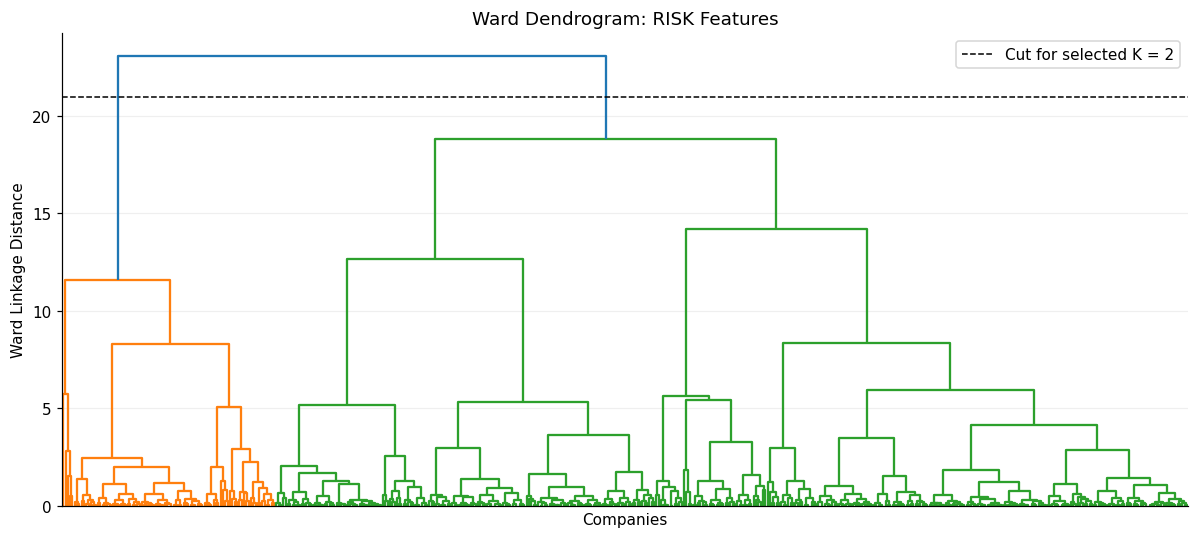

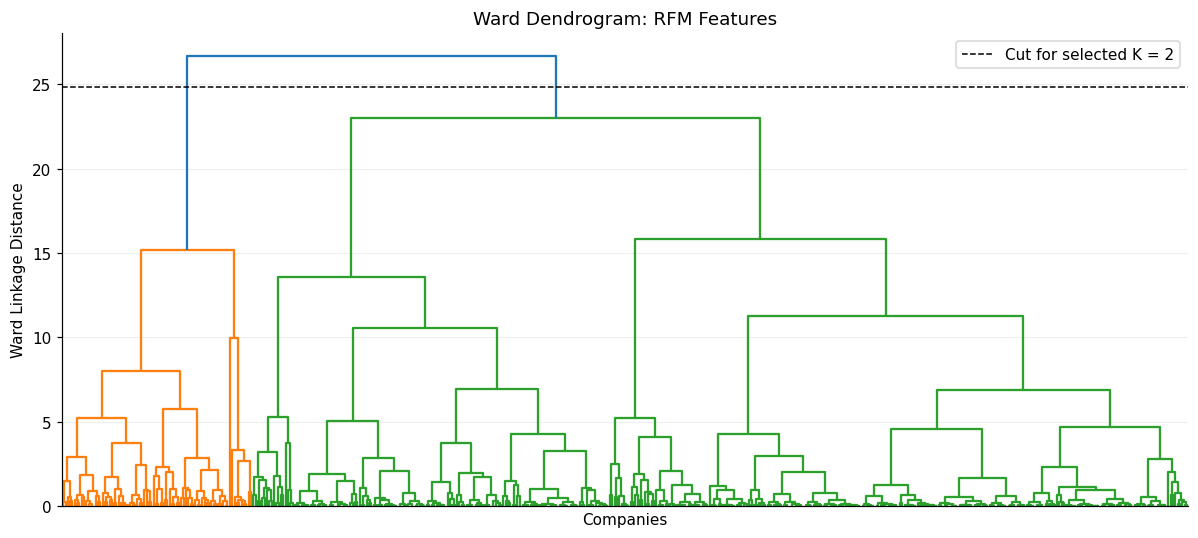

Ward Clustering Evaluation


,FeatureSet,Method,K,Silhouette,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,92,394,True
1,risk,Ward,3,0.2738,92,230,False
2,risk,Ward,4,0.2821,48,182,False
3,risk,Ward,5,0.3041,48,182,False
4,risk,Ward,6,0.3204,5,182,False
5,risk,Ward,7,0.3240,5,160,False
6,risk,Ward,8,0.3208,5,160,False
7,rfm,Ward,2,0.3680,82,404,True
8,rfm,Ward,3,0.3040,82,250,False
9,rfm,Ward,4,0.2888,43,207,False


Ward Candidate Cluster Profiles


,FeatureSet,Method,K,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,2,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,2,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,risk,Ward,3,0,230,0.0015,0.0017,1.1096,1.0384,18.9304,11.0,3.0565,3.0,3.380100e+10,1.411142e+10
3,risk,Ward,3,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
4,risk,Ward,3,2,164,0.0029,0.0033,0.6012,0.5777,20.6463,11.0,2.7805,3.0,2.517294e+10,1.764940e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,rfm,Ward,8,3,43,0.0028,0.0028,1.0081,1.0467,16.8372,11.0,5.3721,5.0,1.496218e+10,1.442997e+10
66,rfm,Ward,8,4,141,0.0025,0.0025,0.9223,0.9183,11.1702,11.0,3.4468,3.0,1.121211e+10,1.078527e+10
67,rfm,Ward,8,5,18,0.0053,0.0046,1.3512,1.2895,17.5000,12.5,4.5556,5.0,3.504407e+11,2.448680e+11
68,rfm,Ward,8,6,66,0.0025,0.0022,0.9336,0.9274,11.0758,11.0,1.8636,2.0,1.085987e+10,1.067576e+10


In [16]:
# Run the clustering configurations and collect their evaluation results.
(
    features,
    ward_scores,
    ward_profiles,
    ward_cluster_sizes,
    ward_labels,
    ward_candidate_profiles
) = perform_clustering(features, 'Ward')

print("Ward Clustering Evaluation")

display(
    ward_scores.drop(columns='Inertia').round(4)
)

print("Ward Candidate Cluster Profiles")

display(ward_candidate_profiles.round(4))

2.3 K-means clustering

In [17]:
# Summarise cluster sizes and compare the resulting group assignments.
(
    features,
    kmeans_scores,
    kmeans_profiles,
    kmeans_cluster_sizes,
    kmeans_labels,
    kmeans_candidate_profiles
) = perform_clustering(features, 'KMeans')

print("K-means Clustering Evaluation")

display(kmeans_scores.round(4))

print("K-means Cluster Sizes")

display(kmeans_cluster_sizes)

all_clustering_scores = pd.concat(
    [ward_scores, kmeans_scores],
    ignore_index=True
)

all_cluster_profiles = pd.concat(
    [ward_profiles, kmeans_profiles],
    ignore_index=True
)

print("Both clustering methods completed successfully.")

K-means Clustering Evaluation


,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,KMeans,2,0.3869,621.6344,143,343,True
1,risk,KMeans,3,0.3289,461.1787,119,202,False
2,risk,KMeans,4,0.3270,371.5770,40,160,False
3,risk,KMeans,5,0.3406,309.6130,27,166,False
4,risk,KMeans,6,0.3349,265.0970,5,156,False
5,risk,KMeans,7,0.3315,227.4762,5,143,False
6,risk,KMeans,8,0.3542,194.3616,5,136,False
7,rfm,KMeans,2,0.4231,1066.8319,68,418,True
8,rfm,KMeans,3,0.3250,796.6144,64,270,False
9,rfm,KMeans,4,0.3409,609.8325,61,212,False


K-means Cluster Sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


Both clustering methods completed successfully.


In [18]:
# Compare clustering methods using the evaluation measures calculated above.
print("Comparison of clustering methods")

display(all_clustering_scores.round(4))

print("Selected Cluster Profiles")

display(all_cluster_profiles.round(4))

print("Ward cluster sizes")

display(ward_cluster_sizes)

print("K-means cluster sizes")

display(kmeans_cluster_sizes)

Comparison of clustering methods


,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,NaN,92,394,True
1,risk,Ward,3,0.2738,NaN,92,230,False
2,risk,Ward,4,0.2821,NaN,48,182,False
3,risk,Ward,5,0.3041,NaN,48,182,False
4,risk,Ward,6,0.3204,NaN,5,182,False
5,risk,Ward,7,0.3240,NaN,5,160,False
6,risk,Ward,8,0.3208,NaN,5,160,False
7,rfm,Ward,2,0.3680,NaN,82,404,True
8,rfm,Ward,3,0.3040,NaN,82,250,False
9,rfm,Ward,4,0.2888,NaN,43,207,False


Selected Cluster Profiles


,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,rfm,Ward,0,404,0.0029,0.0027,0.9666,0.9350,12.7153,11.0,3.1708,3.0,3.783020e+10,1.604728e+10
3,rfm,Ward,1,82,0.0029,0.0024,1.0089,1.0466,58.3049,54.5,2.0976,2.0,4.715898e+10,1.784903e+10
4,risk,KMeans,0,143,0.0053,0.0049,1.3505,1.2781,22.6364,11.0,3.1469,3.0,8.143839e+10,2.552367e+10
5,risk,KMeans,1,343,0.0018,0.0019,0.8166,0.8340,19.4781,11.0,2.9242,3.0,2.187973e+10,1.420560e+10
6,rfm,KMeans,0,418,0.0028,0.0027,0.9723,0.9389,13.4234,11.0,3.1866,3.0,3.269100e+10,1.556962e+10
7,rfm,KMeans,1,68,0.0030,0.0025,0.9823,1.0087,63.3382,55.0,1.7794,2.0,8.067057e+10,2.225004e+10


Ward cluster sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,Ward,2,0,394
1,risk,Ward,2,1,92
2,risk,Ward,3,0,230
3,risk,Ward,3,1,92
4,risk,Ward,3,2,164
...,...,...,...,...,...
65,rfm,Ward,8,3,43
66,rfm,Ward,8,4,141
67,rfm,Ward,8,5,18
68,rfm,Ward,8,6,66


K-means cluster sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


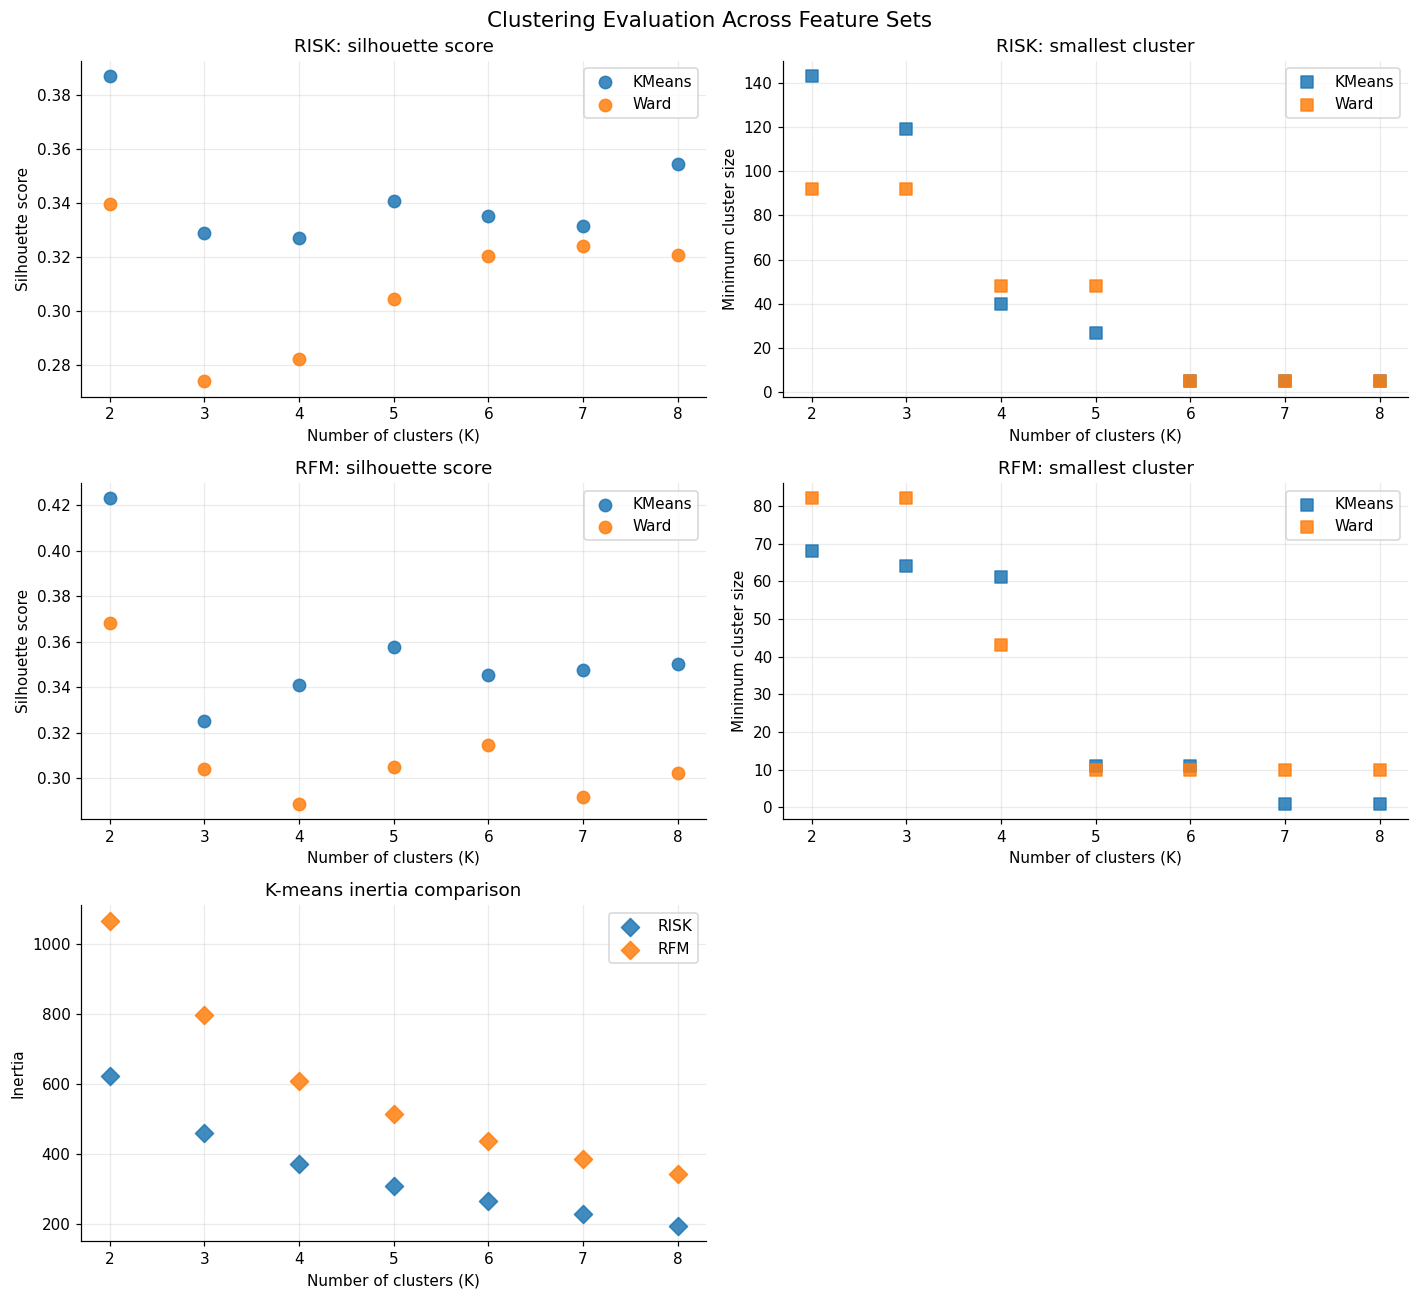

In [19]:
# Scatter-point evaluation plots retain the same K values and metric values.
fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for row, set_name in enumerate(['risk', 'rfm']):
    sub = all_clustering_scores[
        all_clustering_scores['FeatureSet'] == set_name
    ]

    for method, grp in sub.groupby('Method'):
        axes[row, 0].scatter(
            grp['K'], grp['Silhouette'], s=65, marker='o',
            label=method, alpha=0.85
        )
        axes[row, 1].scatter(
            grp['K'], grp['MinClusterSize'], s=65, marker='s',
            label=method, alpha=0.85
        )

    km = sub[sub['Method'] == 'KMeans']
    axes[2, 0].scatter(
        km['K'], km['Inertia'], s=70, marker='D',
        label=set_name.upper(), alpha=0.85
    )

    axes[row, 0].set(
        title=f'{set_name.upper()}: silhouette score',
        xlabel='Number of clusters (K)', ylabel='Silhouette score'
    )
    axes[row, 1].set(
        title=f'{set_name.upper()}: smallest cluster',
        xlabel='Number of clusters (K)', ylabel='Minimum cluster size'
    )
    axes[row, 0].legend()
    axes[row, 1].legend()
    axes[row, 0].grid(alpha=0.25)
    axes[row, 1].grid(alpha=0.25)

axes[2, 0].set(
    title='K-means inertia comparison',
    xlabel='Number of clusters (K)', ylabel='Inertia'
)
axes[2, 0].legend()
axes[2, 0].grid(alpha=0.25)
axes[2, 1].axis('off')
fig.suptitle('Clustering Evaluation Across Feature Sets', fontsize=14)
fig.tight_layout()
display_chart(fig)


2.4 Cluster profiles and algorithm comparison

Final Cluster Profiles


,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,rfm,Ward,0,404,0.0029,0.0027,0.9666,0.9350,12.7153,11.0,3.1708,3.0,3.783020e+10,1.604728e+10
3,rfm,Ward,1,82,0.0029,0.0024,1.0089,1.0466,58.3049,54.5,2.0976,2.0,4.715898e+10,1.784903e+10
4,risk,KMeans,0,143,0.0053,0.0049,1.3505,1.2781,22.6364,11.0,3.1469,3.0,8.143839e+10,2.552367e+10
5,risk,KMeans,1,343,0.0018,0.0019,0.8166,0.8340,19.4781,11.0,2.9242,3.0,2.187973e+10,1.420560e+10
6,rfm,KMeans,0,418,0.0028,0.0027,0.9723,0.9389,13.4234,11.0,3.1866,3.0,3.269100e+10,1.556962e+10
7,rfm,KMeans,1,68,0.0030,0.0025,0.9823,1.0087,63.3382,55.0,1.7794,2.0,8.067057e+10,2.225004e+10


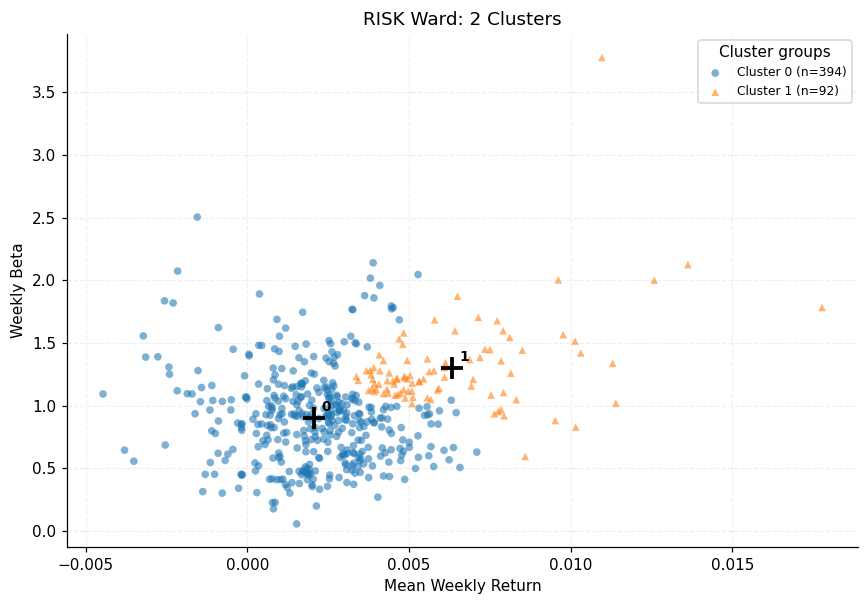

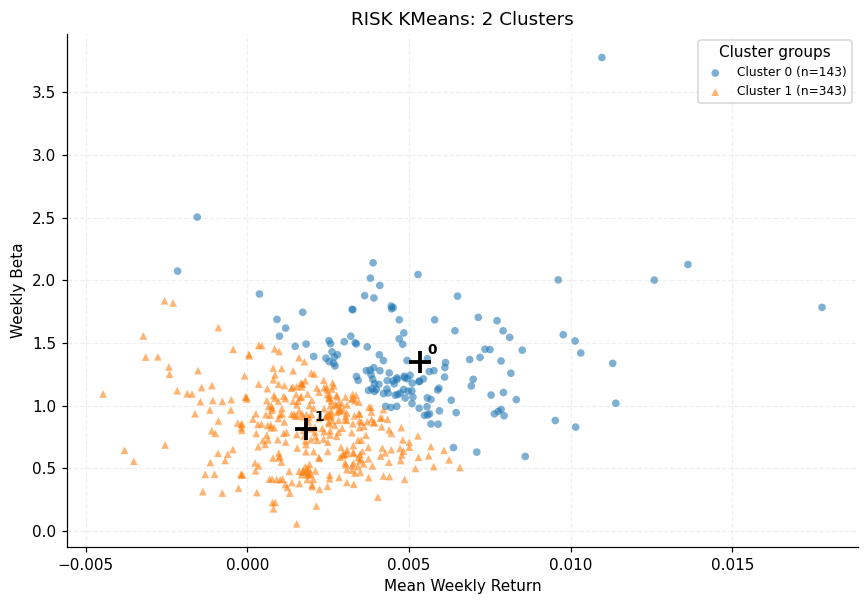

RISK algorithm agreement (ARI): 0.5976


risk_kmeans,0,1
risk_ward,,
0,51,343
1,92,0


,PC1,PC2
R,0.711,0.023
F,-0.650,0.402
LogM,0.268,0.915


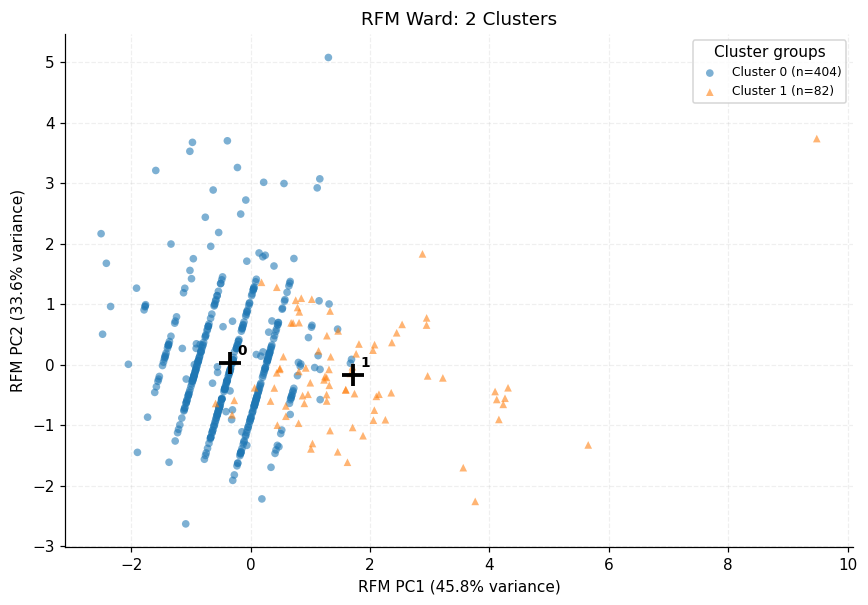

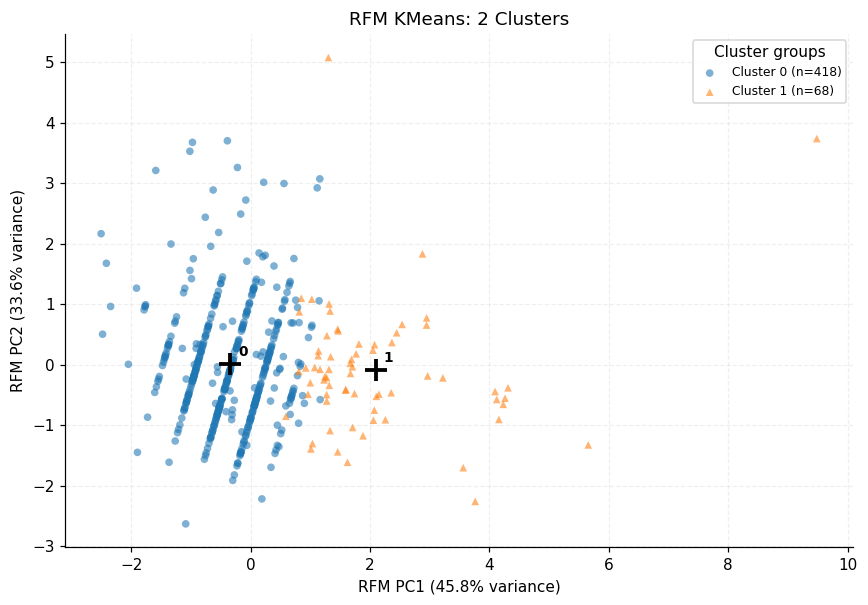

RFM algorithm agreement (ARI): 0.6998


rfm_kmeans,0,1
rfm_ward,,
0,396,8
1,22,60


In [20]:
# Use PCA to display the RFM clustering results in two dimensions.
from sklearn.decomposition import PCA

print("Final Cluster Profiles")
display(all_cluster_profiles.round(4))

for set_name in ['risk', 'rfm']:
    model_input, input_columns = get_model_data(set_name)

    for algo_name in ['Ward', 'KMeans']:
        label_column = f'{set_name}_{algo_name.lower()}'
        label_array = features[label_column].to_numpy()
        n_groups = len(np.unique(label_array))

        if set_name == 'risk':
            x_data = features['MeanWeeklyReturn'].to_numpy()
            y_data = features['WeeklyBeta'].to_numpy()
            x_title = 'Mean Weekly Return'
            y_title = 'Weekly Beta'
        else:
            pca_fit = PCA(n_components=2)
            pca_scores = pca_fit.fit_transform(model_input)
            if algo_name == 'Ward':
                display(pd.DataFrame(
                    pca_fit.components_.T, index=input_columns,
                    columns=['PC1', 'PC2']
                ).round(3))
            x_data = pca_scores[:, 0]
            y_data = pca_scores[:, 1]
            x_title = f'RFM PC1 ({pca_fit.explained_variance_ratio_[0]:.1%} variance)'
            y_title = f'RFM PC2 ({pca_fit.explained_variance_ratio_[1]:.1%} variance)'

        fig, ax = plt.subplots(figsize=(8, 5.6))
        marker_styles = ['o', '^', 's', 'D', 'P', 'X', 'v']

        for position, cluster_id in enumerate(sorted(set(label_array))):
            row_mask = label_array == cluster_id
            cluster_x = x_data[row_mask]
            cluster_y = y_data[row_mask]

            ax.scatter(
                cluster_x, cluster_y,
                s=25, marker=marker_styles[position % len(marker_styles)],
                label=f'Cluster {cluster_id} (n={row_mask.sum()})',
                alpha=0.58, edgecolors='none'
            )

            centre_x = cluster_x.mean()
            centre_y = cluster_y.mean()
            ax.plot(centre_x, centre_y, marker='+', markersize=15,
                    markeredgewidth=2.5, color='black', linestyle='none')
            ax.annotate(
                str(cluster_id), (centre_x, centre_y),
                xytext=(5, 5), textcoords='offset points',
                fontsize=9, fontweight='bold'
            )

        ax.set(
            xlabel=x_title, ylabel=y_title,
            title=f'{set_name.upper()} {algo_name}: {n_groups} Clusters'
        )
        ax.legend(fontsize=8, title='Cluster groups')
        ax.grid(alpha=0.2, linestyle='--')
        display_chart(fig)

    ward_assign = features[f'{set_name}_ward']
    kmeans_assign = features[f'{set_name}_kmeans']
    ari_value = adjusted_rand_score(ward_assign, kmeans_assign)
    print(f'{set_name.upper()} algorithm agreement (ARI): {ari_value:.4f}')
    display(pd.crosstab(ward_assign, kmeans_assign))


### 2.5 Recency, Frequency, and Monetary (RFM) Sensitivity and Correlated Inputs


Recency, Frequency, and Monetary (RFM) Correlation Analysis


,R,F,LogM
R,1.0000,-0.3463,0.1524
F,-0.3463,1.0000,0.0128
LogM,0.1524,0.0128,1.0000


Spearman correlations


,R,F,LogM
R,1.0000,-0.1958,0.1372
F,-0.1958,1.0000,-0.0476
LogM,0.1372,-0.0476,1.0000


Variance share of each principal component (standardised R, F, LogM): [0.458 0.336 0.206]


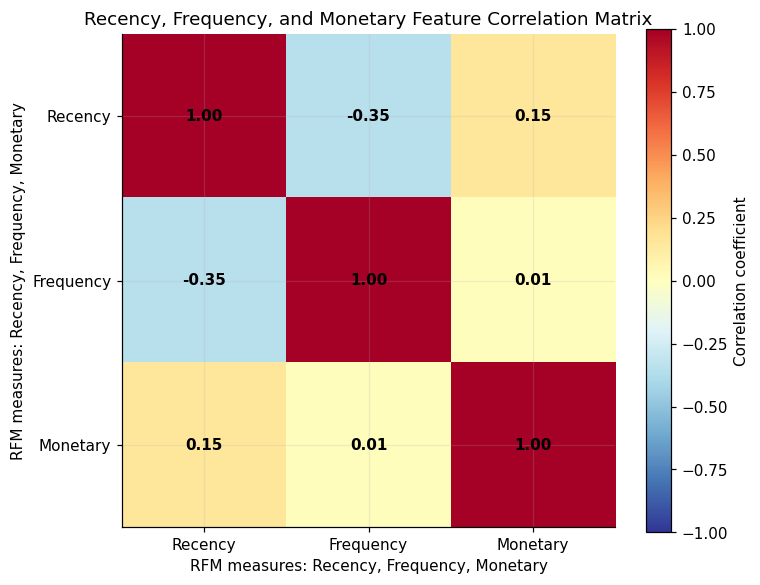

In [21]:
rfm_columns = features[['R', 'F', 'LogM']]
corr_matrix = rfm_columns.corr()

print("Recency, Frequency, and Monetary (RFM) Correlation Analysis")
display(corr_matrix.round(4))

print("Spearman correlations")
display(rfm_columns.corr(method='spearman').round(4))

pc_share = PCA().fit(
    StandardScaler().fit_transform(rfm_columns)
).explained_variance_ratio_
print("Variance share of each principal component (standardised R, F, LogM):", np.round(pc_share, 3))

# Annotated matrix view; the correlation coefficients remain unchanged.
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(corr_matrix.to_numpy(), cmap='RdYlBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(['Recency', 'Frequency', 'Monetary'])
ax.set_yticklabels(['Recency', 'Frequency', 'Monetary'])
ax.set_title('Recency, Frequency, and Monetary Feature Correlation Matrix')
ax.set_xlabel('RFM measures: Recency, Frequency, Monetary')
ax.set_ylabel('RFM measures: Recency, Frequency, Monetary')

for row_pos in range(len(corr_matrix)):
    for col_pos in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[row_pos, col_pos]
        ax.text(col_pos, row_pos, f'{value:.2f}',
                ha='center', va='center', fontweight='bold')

fig.colorbar(image, ax=ax, label='Correlation coefficient')
fig.tight_layout()
display_chart(fig)


In [22]:
# Test how the RFM clustering changes when the Monetary measure is excluded.
ward_k = features['rfm_ward'].nunique()

rf_only = features[['R', 'F']]

rf_standardiser = StandardScaler()

rf_scaled = rf_standardiser.fit_transform(
    rf_only
)

rf_ward_model = AgglomerativeClustering(
    n_clusters=ward_k,
    linkage='ward'
)

features['rfm_ward_without_m'] = (
    rf_ward_model.fit_predict(rf_scaled)
)

ari_without_m = adjusted_rand_score(
    features['rfm_ward'],
    features['rfm_ward_without_m']
)

print(
    "ARI after removing Monetary:",
    round(ari_without_m, 4)
)

for label_column in [
    'rfm_ward',
    'rfm_ward_without_m'
]:

    print("\nResults for:", label_column)

    group_summary = features.groupby(
        label_column
    ).agg(
        Count=('Ticker', 'size'),
        MeanM=('M', 'mean'),
        MedianM=('M', 'median'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean')
    )

    display(group_summary.round(4))

display(pd.crosstab(features['rfm_ward'], features['rfm_ward_without_m'],
                    rownames=['with M'], colnames=['without M']))

features['AvgDailyTradedValue'] = features['M'] / 60

display(features.groupby('rfm_ward_without_m')['AvgDailyTradedValue'].agg(['mean', 'median']).round(0))

print("Silhouette of the R,F-only solution:",
      round(silhouette_score(rf_scaled, features['rfm_ward_without_m']), 4))

ARI after removing Monetary: 0.8735

Results for: rfm_ward


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward,,,,,
0,404,3.783020e+10,1.604728e+10,12.7153,3.1708
1,82,4.715898e+10,1.784903e+10,58.3049,2.0976



Results for: rfm_ward_without_m


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward_without_m,,,,,
0,397,3.780680e+10,1.546400e+10,12.3023,3.2091
1,89,4.652963e+10,2.084781e+10,56.5618,2.0112


without M,0,1
with M,,
0,394,10
1,3,79


,mean,median
rfm_ward_without_m,,
0,630113356.0,257733301.0
1,775493841.0,347463505.0


Silhouette of the R,F-only solution: 0.5239


In [23]:
# Export the feature tables, cluster results, and supporting analysis outputs.
features.to_csv(
    results_dir / 'feature_table_with_clusters.csv',
    index=False
)

all_clustering_scores.to_csv(
    results_dir / 'clustering_evaluation.csv',
    index=False
)

all_cluster_profiles.to_csv(
    results_dir / 'cluster_profiles.csv',
    index=False
)

corr_matrix.to_csv(
    results_dir / 'rfm_correlation.csv'
)

all_cluster_sizes = pd.concat(
    [ward_cluster_sizes, kmeans_cluster_sizes],
    ignore_index=True
)

all_cluster_sizes.to_csv(
    results_dir / 'cluster_sizes.csv',
    index=False
)

stock_returns[features['Ticker']].to_csv(results_dir / 'weekly_returns_included_shares.csv')

index_returns.to_csv(results_dir / 'weekly_returns_benchmark.csv', header=['GSPC_weekly_return'])

overview_columns = [
    'Ticker',
    *metrics,
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans',
    'rfm_ward_without_m'
]

display(features[overview_columns])

print("Task 2 completed successfully!")

print("Final companies analysed:", len(features))

print("Results saved in:", results_dir)

,Ticker,MeanWeeklyReturn,WeeklyBeta,R,F,M,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans,rfm_ward_without_m
0,MMM,0.001142,0.869079,11,4,2.599146e+10,0,1,0,0,0
1,AOS,0.001991,1.042805,11,2,4.748980e+09,0,1,0,0,0
2,ABT,0.000971,0.583542,11,1,3.523027e+10,0,1,0,0,0
3,ABBV,0.003749,0.425366,11,3,6.837054e+10,0,1,0,0,0
4,ACN,0.002376,1.143300,11,2,5.199430e+10,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
481,XYL,0.001358,1.138379,36,3,1.017679e+10,0,1,1,0,1
482,YUM,0.001807,0.631433,56,1,1.339492e+10,0,1,1,1,1
483,ZBRA,0.001181,1.618418,11,4,8.326927e+09,0,0,0,0,0
484,ZBH,-0.001105,0.798203,11,2,9.609458e+09,0,1,0,0,0


Task 2 completed successfully!
Final companies analysed: 486
Results saved in: /content/stock_analysis/output


### Task 3 – Business Intelligence and Critical Review

3.2.1 Cluster profiles and sector composition



Sector composition: risk_ward


risk_ward,0,1
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


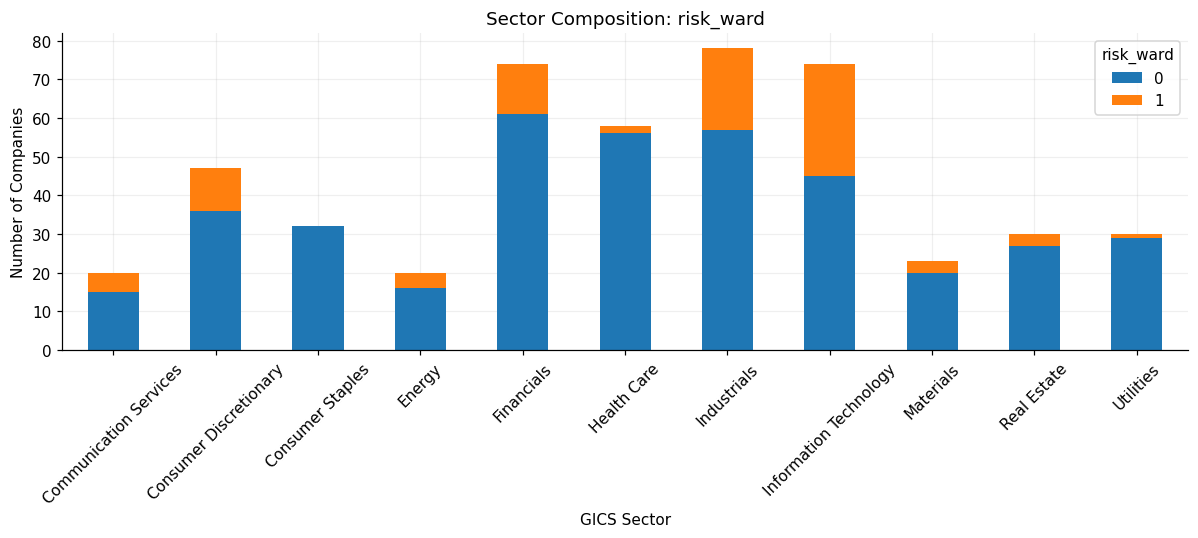


Sector composition: risk_kmeans


risk_kmeans,0,1
Sector,,
Communication Services,5,15
Consumer Discretionary,23,24
Consumer Staples,1,31
Energy,9,11
Financials,17,57
Health Care,2,56
Industrials,29,49
Information Technology,48,26
Materials,4,19


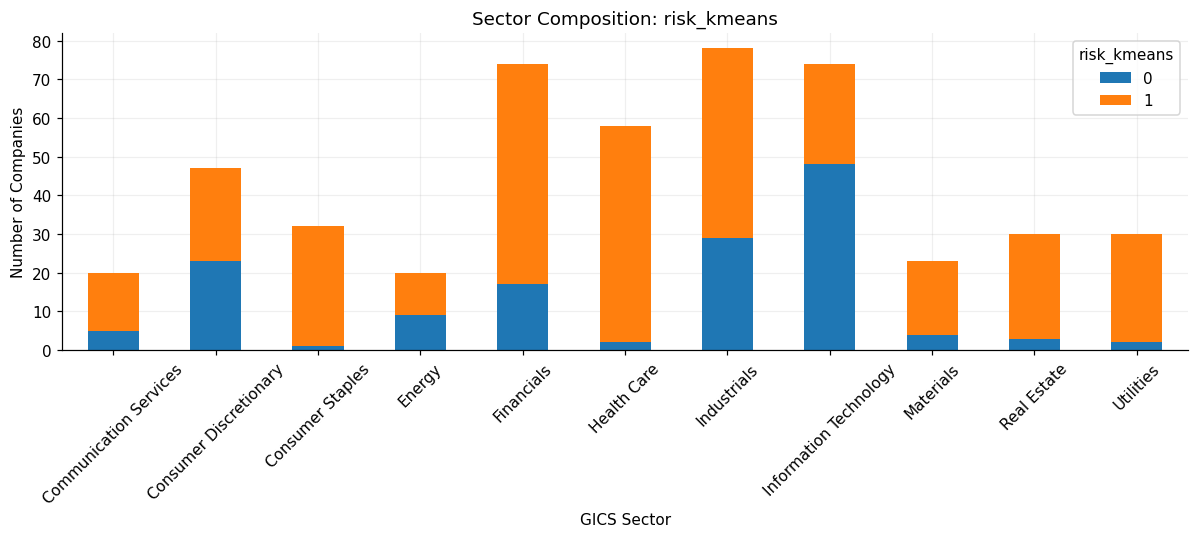


Sector composition: rfm_ward


rfm_ward,0,1
Sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


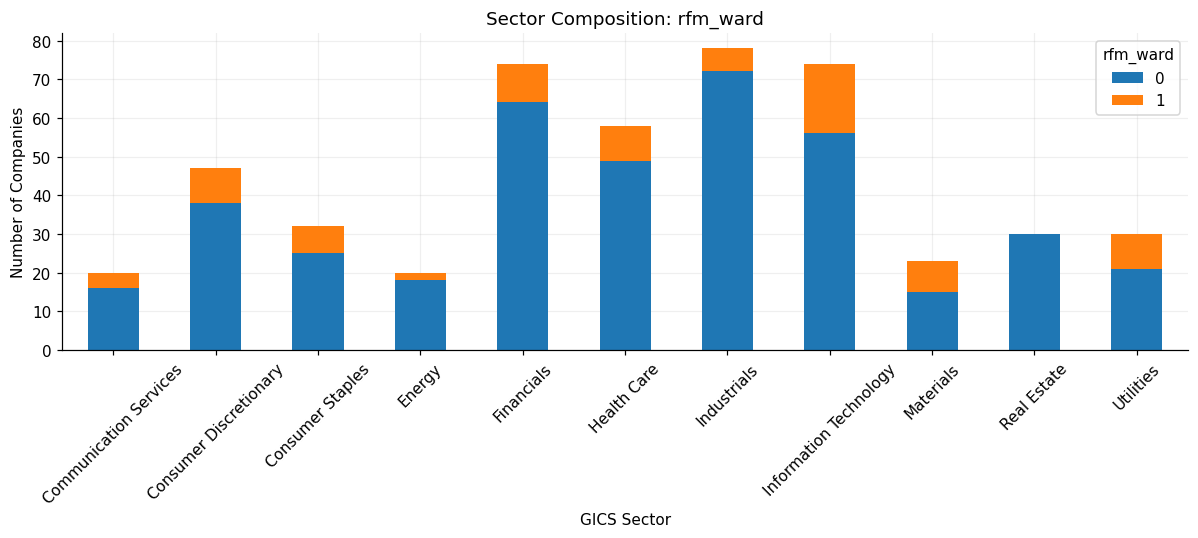


Sector composition: rfm_kmeans


rfm_kmeans,0,1
Sector,,
Communication Services,18,2
Consumer Discretionary,39,8
Consumer Staples,27,5
Energy,19,1
Financials,64,10
Health Care,50,8
Industrials,73,5
Information Technology,60,14
Materials,17,6


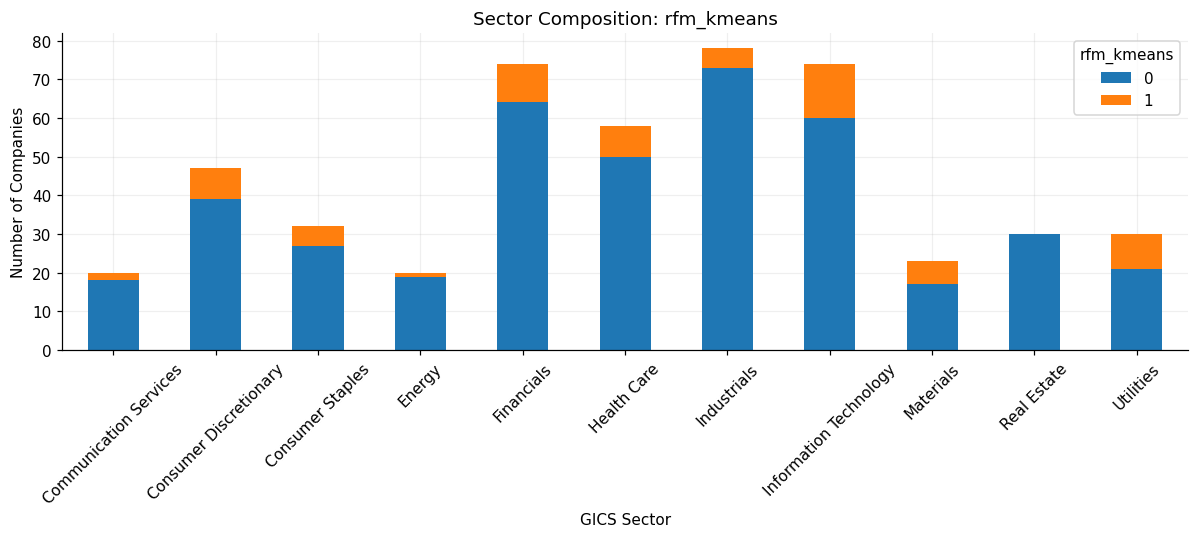

risk_ward vs rfm_ward: ARI = 0.0285


rfm_ward,0,1
risk_ward,,
0,331,63
1,73,19


risk_ward vs rfm_kmeans: ARI = 0.0192


rfm_kmeans,0,1
risk_ward,,
0,341,53
1,77,15


risk_kmeans vs rfm_ward: ARI = 0.0135


rfm_ward,0,1
risk_kmeans,,
0,116,27
1,288,55


risk_kmeans vs rfm_kmeans: ARI = 0.0045


rfm_kmeans,0,1
risk_kmeans,,
0,122,21
1,296,47


In [24]:
# The four clustering outputs to examine
label_columns = [
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans'
]

# Sector breakdown for each clustering output
for label_column in label_columns:

    # print the result
    print("\nSector composition:", label_column)

    # Sector-by-cluster count table
    sector_counts = pd.crosstab(
        features['Sector'],
        features[label_column]
    )

    # Show the counts
    display(sector_counts)

    # Stacked bar chart of the counts
    fig, ax = plt.subplots(figsize=(11, 5))

    # stacked bar of the counts
    sector_counts.plot.bar(
        stacked=True,
        ax=ax,
        rot=45
    )

    # Titles and axis labels
    ax.set(
        title=f'Sector Composition: {label_column}',
        xlabel='GICS Sector',
        ylabel='Number of Companies'
    )

    # Render using the display_chart helper
    display_chart(fig)

# Compare return/beta clusters with RFM clusters on the same shares
for r_col in ['risk_ward', 'risk_kmeans']:
    # compare with each RFM clustering
    for f_col in ['rfm_ward', 'rfm_kmeans']:
        # print the result
        print(f"{r_col} vs {f_col}: ARI = {adjusted_rand_score(features[r_col], features[f_col]):.4f}")
        # show the table
        display(pd.crosstab(features[r_col], features[f_col]))


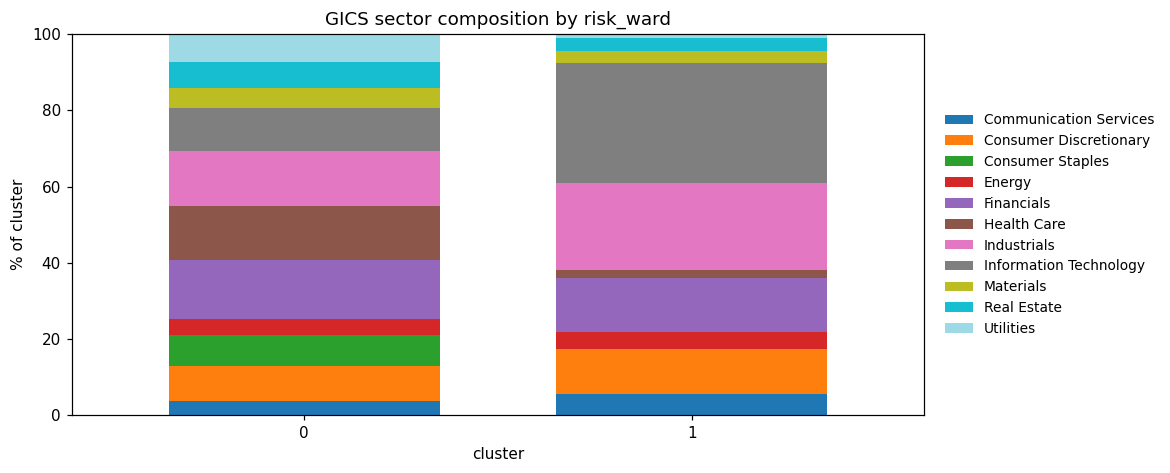

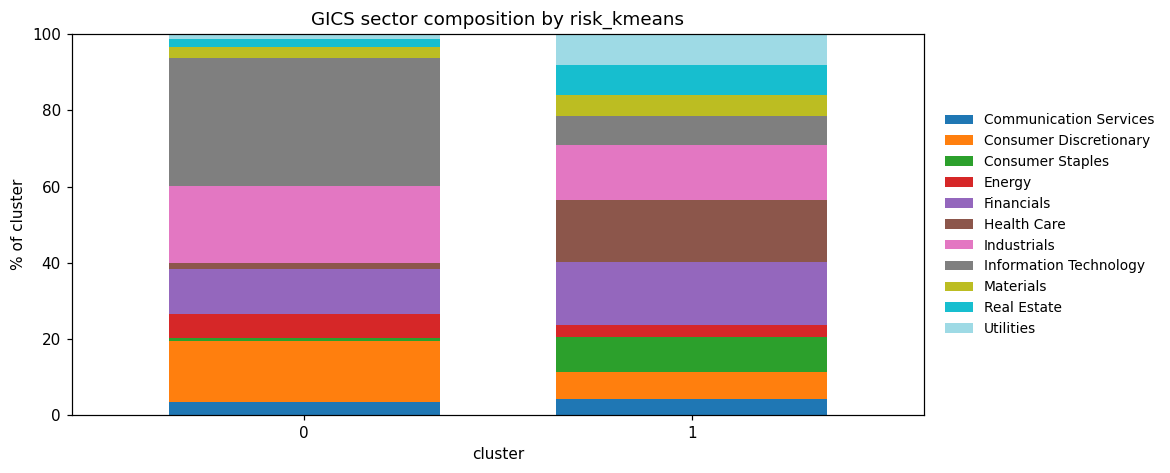

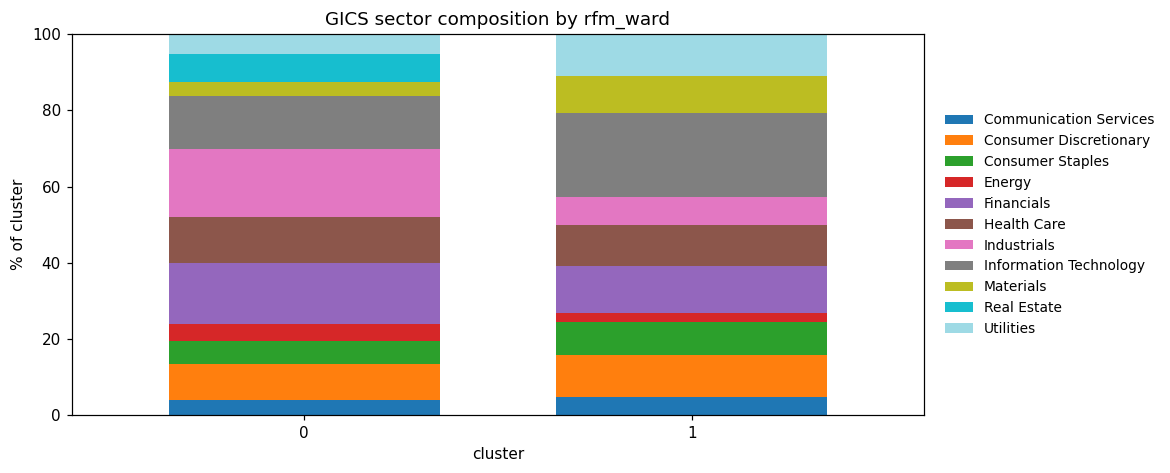

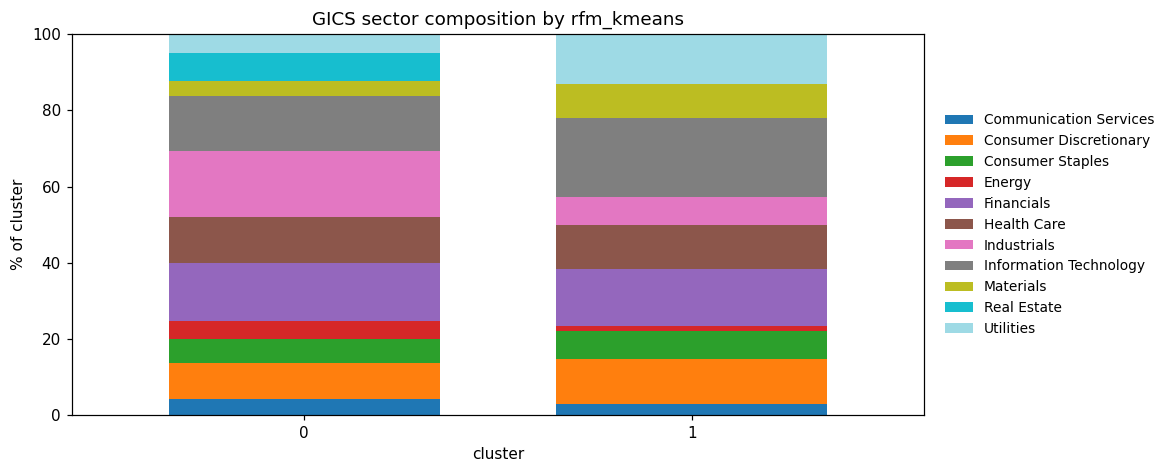

In [25]:
# 100% stacked sector composition by cluster (one chart per clustering solution)
sector_colors = list(plt.cm.tab10.colors) + [plt.cm.tab20.colors[19]]   # 11 GICS sectors

# repeat for each of the four clusterings
for label_column in label_columns:

    # Share of each sector inside every cluster (rows sum to 100)
    pct = pd.crosstab(features[label_column], features['Sector'], normalize='index') * 100

    # create the figure
    fig, ax = plt.subplots(figsize=(10, 4.5))
    # draw the 100% stacked bars
    pct.plot.bar(
        stacked=True, ax=ax, rot=0, width=0.7,
        color=sector_colors[:pct.shape[1]], edgecolor='none'
    )

    # titles and axis labels
    ax.set(
        title=f'GICS sector composition by {label_column}',
        xlabel='cluster', ylabel='% of cluster', ylim=(0, 100)
    )
    # no grid lines
    ax.grid(False)
    # show the full frame
    for side in ['top', 'right']:
        # show the frame line
        ax.spines[side].set_visible(True)

    # Legend outside the plot, on the right
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)

    # Save first (keeps the legend in the file), then show
    fig.savefig(results_dir / f'sector_composition_{label_column}.png', dpi=200, bbox_inches='tight')
    # draw the figure
    plt.show()
    # free the memory
    plt.close(fig)


**3.2.2 and 3.2.3 Supporting evidence for the review**

3.2.2 Sensitivity findings and business uses

In [26]:
# Check that the sector and cluster columns needed for Task 3 are available.
assert 'Sector' in features.columns, "Sector information is missing."

needed_columns = [
    'Ticker',
    'Sector',
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans'
]

absent_columns = [
    col for col in needed_columns
    if col not in features.columns
]

assert not absent_columns, (
    f"Missing columns: {absent_columns}"
)

display(features[needed_columns].head(10))

print("Task 3 data is ready.")

,Ticker,Sector,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans
0,MMM,Industrials,0,1,0,0
1,AOS,Industrials,0,1,0,0
2,ABT,Health Care,0,1,0,0
3,ABBV,Health Care,0,1,0,0
4,ACN,Information Technology,0,1,0,0
5,ADBE,Information Technology,0,0,0,0
6,AMD,Information Technology,0,0,0,0
7,AES,Utilities,0,1,1,1
8,AFL,Financials,0,1,0,0
9,A,Health Care,0,1,0,0


Task 3 data is ready.


In [27]:
# Calculate sector percentages within each cluster and compare them with the overall sector mix.
for label_column in label_columns:

    print("\nPercentage distribution:", label_column)

    sector_shares = pd.crosstab(
        features[label_column],
        features['Sector'],
        normalize='index'
    ) * 100

    display(sector_shares.round(2))

overall_share = features['Sector'].value_counts(normalize=True) * 100

for label_column in label_columns:

    share = pd.crosstab(features[label_column], features['Sector'], normalize='index') * 100

    print("\nSector lift vs overall mix:", label_column)

    display(share.div(overall_share, axis=1).round(2))


Percentage distribution: risk_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_ward,,,,,,,,,,,
0,3.81,9.14,8.12,4.06,15.48,14.21,14.47,11.42,5.08,6.85,7.36
1,5.43,11.96,0.00,4.35,14.13,2.17,22.83,31.52,3.26,3.26,1.09



Percentage distribution: risk_kmeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_kmeans,,,,,,,,,,,
0,3.50,16.08,0.70,6.29,11.89,1.40,20.28,33.57,2.80,2.10,1.40
1,4.37,7.00,9.04,3.21,16.62,16.33,14.29,7.58,5.54,7.87,8.16



Percentage distribution: rfm_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
0,3.96,9.41,6.19,4.46,15.84,12.13,17.82,13.86,3.71,7.43,5.20
1,4.88,10.98,8.54,2.44,12.20,10.98,7.32,21.95,9.76,0.00,10.98


... (6 outputs left out)


Sector lift vs overall mix: rfm_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
0,0.96,0.97,0.94,1.08,1.04,1.02,1.11,0.91,0.78,1.2,0.84
1,1.19,1.13,1.30,0.59,0.80,0.92,0.46,1.44,2.06,0.0,1.78



Sector lift vs overall mix: rfm_kmeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_kmeans,,,,,,,,,,,
0,1.05,0.96,0.98,1.10,1.01,1.00,1.09,0.94,0.86,1.16,0.81
1,0.71,1.22,1.12,0.36,0.97,0.99,0.46,1.35,1.86,0.00,2.14


3.2.3 Critical evaluation and limitations

In [28]:
# Measure average pairwise return correlation within each cluster.
returns_final = stock_returns[features['Ticker']]

corr_returns = returns_final.corr().to_numpy()

def avg_pairwise_corr(idx):

    sub = corr_returns[np.ix_(idx, idx)]

    m = len(idx)

    return (sub.sum() - m) / (m * (m - 1)) if m > 1 else np.nan

overall_corr = avg_pairwise_corr(np.arange(len(features)))

dependency_rows = []

for label_column in label_columns:

    for cluster_id in sorted(features[label_column].unique()):

        idx = np.where(features[label_column].to_numpy() == cluster_id)[0]

        dependency_rows.append({
            'Clustering': label_column,
            'Cluster': cluster_id,
            'Size': len(idx),
            'AvgPairwiseCorr': avg_pairwise_corr(idx),
            'AvgPairwiseCorr_AllShares': overall_corr
        })

display(pd.DataFrame(dependency_rows).round(3))

,Clustering,Cluster,Size,AvgPairwiseCorr,AvgPairwiseCorr_AllShares
0,risk_ward,0,394,0.297,0.3
1,risk_ward,1,92,0.374,0.3
2,risk_kmeans,0,143,0.372,0.3
3,risk_kmeans,1,343,0.302,0.3
4,rfm_ward,0,404,0.306,0.3
5,rfm_ward,1,82,0.266,0.3
6,rfm_kmeans,0,418,0.305,0.3
7,rfm_kmeans,1,68,0.271,0.3
